# Radiation pattern of the patch antenna element

In 01 to 03 each array element was an isotropic point source.
The antenna of a real radar board is a microstrip patch antenna, whose pattern is not isotropic.
In this notebook the pattern of the antenna element of the TI cascade radar evaluation module (MMWCAS-RF-EVM) is computed with the electromagnetic field solver openEMS, in three steps:

1. a single rectangular patch designed with the textbook formulas;
2. the 4-patch series-fed element with the dimensions of the TI document;
3. the same element read from the manufacturing data (Gerber files) of the board, with the elements and the copper around it.

The notebook is run in the conda environment with openEMS set up as in Appendix A; with other versions of the software the numbers may differ slightly.
The simulations take minutes to hours; their results are stored in `openems/data` and read here.

**Reference**: [AWRx Cascaded Radar RF Evaluation Module (MMWCAS-RF-EVM) User's Guide, SWRU553A](https://www.ti.com/lit/ug/swru553a/swru553a.pdf), Section 2.6.2 (Fig. 16, Table 7), Fig. 18, Fig. 30.

## Terms

* **FDTD (finite-difference time-domain)**: a method that solves Maxwell's equations on a grid of cells, step by step in time. openEMS is an FDTD solver.
* **PML (perfectly matched layer)**: an absorbing layer at the boundary of the computational domain, which imitates free space.
* **PEC (perfect electric conductor)**: a conductor without loss, on whose surface the tangential electric field is zero. The copper and the ground are modeled as PEC sheets of zero thickness.
* **Port**: where the antenna is excited and where the reflected wave is measured. A *lumped port* is a source with a resistance between two points; a *microstrip port* excites the wave on a microstrip line.
* **$S_{11}$ (reflection coefficient)**: the ratio of the reflected to the incident wave at the port. The antenna radiates best at the frequency where $|S_{11}|$ is lowest (the resonance).
* **Directivity**: the radiation intensity in a direction relative to that of an isotropic antenna radiating the same power, in dBi. The *gain* is the directivity times the efficiency; no loss is evaluated here, so the results are directivities.
* **E-plane, H-plane**: the planes through the main beam parallel and perpendicular to the electric field of the patch.
* **3 dB beamwidth**: the width of the main lobe between the directions where the power is half of the maximum. Main lobe, sidelobe and null are as in [01](./01_beam_pattern.ipynb).
* **Near-field to far-field transformation**: the field computed on a box around the antenna is converted to the pattern far from the antenna.

## 1. Single patch

In this section the operating frequency and the substrate are decided first: 77 GHz and Rogers RO3003, the substrate of the board.
The size of the patch is then determined with the Hammerstad equations.
Finally the size of the patch and the size of the ground plane are changed, and the change of the characteristics is checked.

### 1.1 Stack-up

The RF layers of the board are L1 (top copper) and L2 (ground) with a 5 mil RO3003 core between them (Fig. 30 of the TI document).
The layers below L2 are separated from the antenna by the ground plane, so they are ignored.

| Item | Value |
| ---- | ---- |
| substrate | Rogers RO3003 |
| thickness $h$ | 5 mil = 0.127 mm |
| relative permittivity $\varepsilon_r$ | 3.0 (data sheet value at 10 GHz, assumed to be constant) |
| loss tangent $\tan\delta$ | 0.001 |
| top copper (L1) | 1.6 mil, modeled as a zero-thickness PEC sheet |
| ground (L2) | modeled as a zero-thickness PEC sheet |
| solder resist | 0.8 mil, ignored |

<img src="../images/05_stackup.png" width="900" style="background-color: white;">

<p style="text-align:center"><b>Fig. 1 Stack-up of the board (TI Fig. 30, to scale) and the structure used in the simulation (the metal sheets are drawn with a finite thickness for visibility)</b></p>

Note that $h$ is only about $0.03\lambda_0$ at 77 GHz ($\lambda_0 = 3.9$ mm), which is very thin.
In the three-dimensional figures below, the vertical scale (substrate and copper thickness) is exaggerated by a factor of 6 for visibility.
The copper thickness drawn is only for clarity; the simulation uses zero thickness.

### 1.2 Coordinate system

The patch lies in the $xy$-plane and radiates toward $+z$.
The resonant length $L$ of the patch is along the $x$-axis.
Accordingly, the $xz$-plane is the E-plane (Phi = 0 in the FDTD output) and the $yz$-plane is the H-plane (Phi = 90).
Note that the TI document uses the opposite naming of Phi: in Fig. 18 the E-plane is Phi = 90 and the H-plane is Phi = 0.

<img src="../images/05_model_single.png" width="600" style="background-color: white;">

<p style="text-align:center"><b>Fig. 2 Single patch model (vertical scale x6)</b></p>

The cross section at $y = 0$ below shows the feed. The red column is the lumped port between the ground (bottom) and the patch (top), and its diameter is exaggerated.

<img src="../images/05_model_section.png" width="600" style="background-color: white;">

<p style="text-align:center"><b>Fig. 3 Cross section of the single patch model at y = 0 (vertical scale x6, port diameter exaggerated)</b></p>

### 1.3 Design

The patch is designed with the transmission-line model, a standard textbook procedure.
The width $W$ gives an efficient radiator, the effective permittivity $\varepsilon_\mathrm{eff}$ accounts for the fringing field, and the length $L$ is about a half guided wavelength shortened by the fringing extension $\Delta L$ at each radiating edge.

$$
W = \frac{c}{2f_0}\sqrt{\frac{2}{\varepsilon_r + 1}},\quad
\varepsilon_\mathrm{eff} = \frac{\varepsilon_r + 1}{2} + \frac{\varepsilon_r - 1}{2}\left(1 + 12\frac{h}{W}\right)^{-1/2},\quad
L = \frac{c}{2f_0\sqrt{\varepsilon_\mathrm{eff}}} - 2\Delta L
$$

where $f_0 = 77$ GHz and $\Delta L$ is given by the Hammerstad formula.
The patch is fed by a vertical lumped port (50 $\Omega$) between the ground and the patch at an offset from the patch center along the $x$-axis.
The ground and the substrate are finite: $4 \times 4$ mm.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from patch_antenna import design_patch

W, L, eeff, dL = design_patch(77e9, 3.0, 0.127)
print('W = {:.3f} mm, eps_eff = {:.3f}, dL = {:.4f} mm, L = {:.3f} mm'.format(W, eeff, dL, L))

W = 1.377 mm, eps_eff = 2.689, dL = 0.0614 mm, L = 1.064 mm


### 1.4 Simulation

The designed patch and its variations are simulated with openEMS.
The procedure follows the openEMS tutorial [Simple Patch Antenna](https://docs.openems.de/en/v0.37.0/python/openEMS/Tutorials/Simple_Patch_Antenna.html): the FDTD setup (excitation and boundary), the substrate, the ground and the patch with the mesh, the lumped port, the near-field to far-field box, the run, and the post-processing ($S_{11}$ and the far field).

| Item | Setting |
| ---- | ---- |
| excitation | Gaussian pulse, center 77 GHz, 20 dB corner frequency 10 GHz (67 to 87 GHz) |
| port | lumped port 50 $\Omega$ between the ground and the patch |
| boundary | PML (8 cells) on all sides, one wavelength of air between the ground plane and the PML |
| copper | zero-thickness PEC |

The excitation with a Gaussian pulse is the standard procedure of the openEMS tutorials.
A pulse contains a band of frequencies: from one run in the time domain, the response at every frequency of the band is obtained by the Fourier transform.
The resonance is therefore found even when it is not at the design frequency, and one run gives the whole $S_{11}$ curve.
The far field is computed at the resonant frequency of each model.

Each model is a *preset*, a dictionary of the settings that differ from the design; the settings not given keep the values of the design:

| Setting | Design |
| ---- | ---- |
| design frequency `f0` | 77 GHz |
| substrate `epsr`, `tand`, `h` | RO3003: 3.0, 0.001, 0.127 mm |
| patch width `W` and length `L` | designed above |
| ground plane and substrate `gnd` | $4 \times 4$ mm |
| feed `feed_x` | 0.2 mm from the centre of the patch along $x$ |

The presets change one setting at a time: the length and the width of the patch, and the size of the ground plane.

In [2]:
from patch_antenna import simulate_patch, save_result, load_result, file_name, summary, show_result, compare

presets = {
    'design':       dict(),
    'L = 1.00 mm':  dict(L=1.00),
    'W = 1.0 mm':   dict(W=1.0),
    'W = 1.8 mm':   dict(W=1.8),
    'ground 2 mm':  dict(gnd=2.0),
    'ground 8 mm':  dict(gnd=8.0),
    'ground 16 mm': dict(gnd=16.0),
}

RUN = False    # True: run the simulations (about 8 minutes in total); False: read the stored results
data_dir = 'openems/data/patch_presets'
results = {}
for name, preset in presets.items():
    path = os.path.join(data_dir, file_name(name))
    if RUN:
        save_result(simulate_patch(preset, os.path.abspath(os.path.join('../tmp/patch_presets', file_name(name)[:-4]))), path)
    results[name] = load_result(path)

print('{:14s} {:>9s} {:>8s} {:>9s} {:>8s} {:>8s} {:>13s}'.format('model', 'f_res[GHz]', 'S11[dB]', 'D[dBi]', 'BW_E', 'BW_H', 'front/back[dB]'))
for name, r in results.items():
    s = summary(r)
    print('{:14s} {:9.1f} {:9.1f} {:8.1f} {:8.0f} {:8.0f} {:13.1f}'.format(name, s['f_res'], s['s11_min'], s['Dmax'], s['bw_E'], s['bw_H'], s['front_to_back']))

model          f_res[GHz]  S11[dB]    D[dBi]     BW_E     BW_H front/back[dB]
design              73.3     -16.0      7.7       74       80          17.9
L = 1.00 mm         77.5     -15.0      7.7       75       78          17.0
W = 1.0 mm          74.7     -19.4      7.6       74       82          17.5
W = 1.8 mm          72.3      -8.1      7.8       73       76          18.3
ground 2 mm         73.3     -11.8      6.9       87       86          17.1
ground 8 mm         73.3     -16.6      7.1      109       80          14.9
ground 16 mm        73.2     -16.0      7.0      124       98          17.3


When the notebook is run, the cell below shows the settings and the results of one model at a time; the model is chosen from the list, and the design is drawn in gray.
The output of this cell is not stored in the file.

In [3]:
import ipywidgets as widgets

@widgets.interact(model=widgets.Dropdown(options=list(presets), value='design', description='model'))
def show(model):
    show_result(results[model], results['design'])
    plt.show()

#### Size of the patch

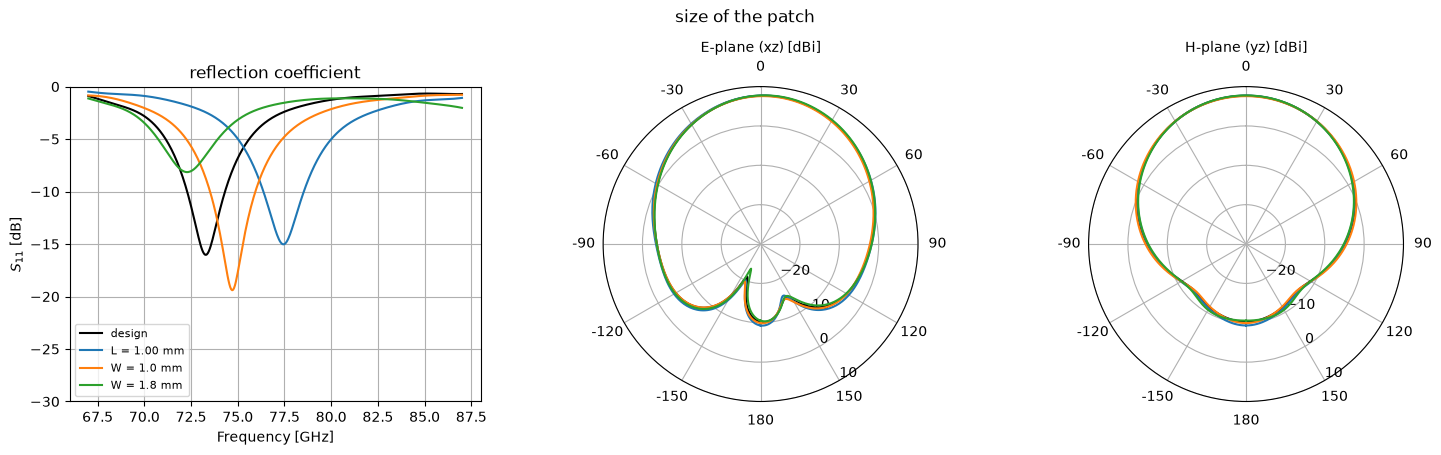

In [4]:
fig = compare(results, ['design', 'L = 1.00 mm', 'W = 1.0 mm', 'W = 1.8 mm'], 'size of the patch')

* The length $L$ decides the resonant frequency: shortening $L$ from 1.064 mm to 1.00 mm moves the resonance from 73.3 GHz to 77.5 GHz, close to the design frequency. The patch designed by the formulas resonates 5 % low, and $L$ is the setting to adjust it.
* The width $W$ changes the matching: the minimum of $S_{11}$ is $-19.5$ dB with $W = 1.0$ mm and $-8.2$ dB with $W = 1.8$ mm. The resonant frequency moves a little (74.7 and 72.3 GHz).
* The pattern hardly changes: the directivity stays at 7.6 to 7.8 dBi and the beam at about 75 deg (E-plane) $\times$ 80 deg (H-plane).

#### Size of the ground plane

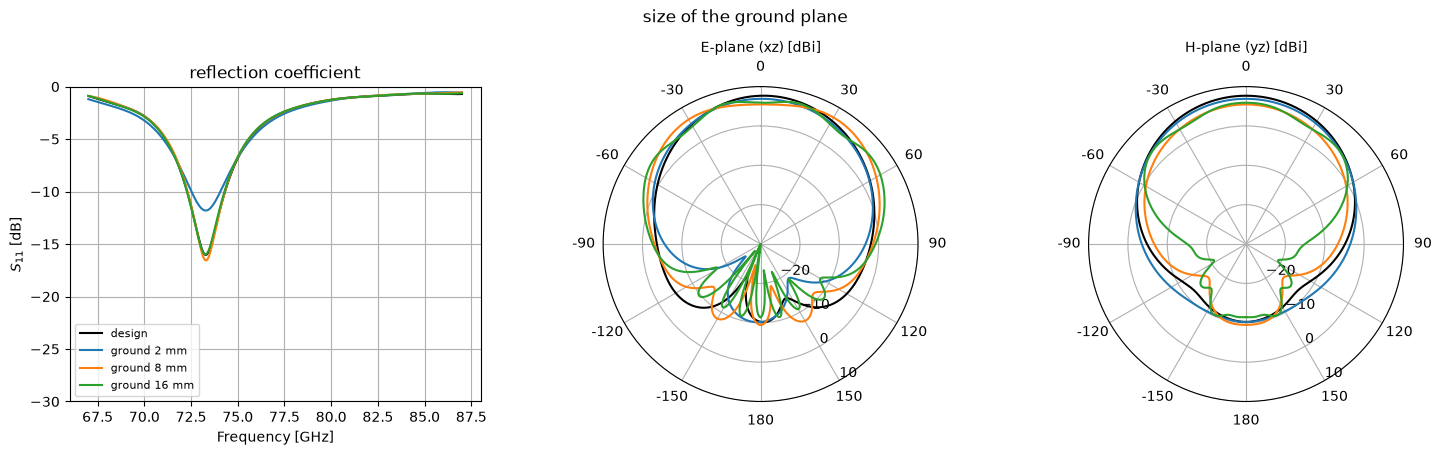

In [5]:
fig = compare(results, ['design', 'ground 2 mm', 'ground 8 mm', 'ground 16 mm'], 'size of the ground plane')

* The resonance does not change (73.3 GHz); the size of the ground changes the pattern.
* The larger the ground plane, the more ripples appear in the pattern, in front and at the back: the edges of the ground radiate too, and their waves interfere with the wave of the patch. The ripples of the 16 mm ground are finer than those of the 8 mm ground.
* With the 8 and 16 mm grounds the top of the E-plane beam becomes flat, and its 3 dB width grows to 109 and 124 deg; with the 2 mm ground the pattern is smooth and the beam is 87 deg (E-plane) and 86 deg (H-plane) wide.

An infinite ground plane would have no edges. Cutting it to a finite size is like cutting an infinitely long periodic signal with a window: the cut edges create ripples, and a longer window (a larger ground) gives finer ripples.

The size of a single patch decides the resonant frequency and the matching, but hardly the beam: with any $W$ and $L$ the beam is about 75 deg $\times$ 80 deg, much broader than the narrow beams of the arrays in 01.
What happens when several patches are arranged in a row? This is the subject of the next section.

The same steps are also written as the methods of a class, `PatchAntenna` in `patch_antenna_common.py`, one method per step of the tutorial, so that the following sections can change one step at a time.
`single_patch` in the same file is the model of this section with these methods, and `compare_with_simulate_patch` checks that it builds the same model (the file written by CSXCAD) as `simulate_patch` for each stored preset.
Only the models are compared, not the results of runs: openEMS checks the end criterion every few seconds of wall-clock time, so the time step at which a run stops, and with it the result, changes slightly from run to run.


## 2. 4-patch series-fed element

The aim of this section is to reproduce Fig. 18 of the TI document, the pattern of the receiving element RX1 at 76 GHz, qualitatively.
The element is simulated alone, and the comparison with the figure of TI is made in the last subsection (2.4).

### 2.1 Structure

The antenna element of the board is a series-fed array of four patches (Fig. 16 of the TI document).
The patches are connected with thin microstrip lines.
The two patches in the middle are wider than the two at both ends, which tapers the excitation.
The lengths of the patches and of the lines are chosen so that the four patches radiate in phase at the design frequency: from one patch to the next the wave travels about one guided wavelength.
The dimensions are given in Table 7 of the document in mil.

| Label | mil | mm | Meaning |
| ---- | ---- | ---- | ---- |
| A1 | 27.568 | 0.700 | feed section (width F2) |
| A2 | 11.802 | 0.300 | feed section (width F2) |
| B1 | 47.24 | 1.200 | line to the first patch (width F3) |
| B2, B3, B4 | 49.21, 45.27, 49.21 | 1.250, 1.150, 1.250 | lines between patches (width F3) |
| C1 | 42.52 | 1.080 | patch length (end patches) |
| C2 | 40.95 | 1.040 | patch length (middle patches) |
| E1 | 39.38 | 1.000 | patch width (end patches) |
| E2 | 55.12 | 1.400 | patch width (middle patches) |
| F1 | 8.4 | 0.213 | width of the line in front of A1 (outside the antenna polygon) |
| F2 | 10.62 | 0.270 | width of A1 and A2 |
| F3 | 3.94 | 0.100 | width of the thin lines |

<img src="../images/05_patch_antenna4_model_plain.png" width="700" style="background-color: white;">

<p style="text-align:center"><b>Fig. 4 4-patch series-fed array model (vertical scale x6, GCPW ground and vias not modeled)</b></p>

The coplanar ground and the via fence of the grounded coplanar waveguide (GCPW) around the feed line (D1, D2, H in the figure) are not modeled.
The ground is finite: $2$ mm behind the last patch (the keepout G of Table 7) and $\pm 3$ mm in width; on the feed side it runs into the PML together with the feed line.

### 2.2 Simulation

The procedure is the same as in Section 1, with a microstrip port instead of the lumped port.
The model is built with the methods of `PatchAntenna` (`patch_antenna_common.py`) in `patch_antenna4.py`: the geometry of the element is declared by the function `series_element` from the dimensions of Table 7 and given to `simulate_element`, which calls the steps in order.

| Item | Setting |
| ---- | ---- |
| excitation | Gaussian pulse, center 78 GHz, 20 dB corner frequency 10 GHz (68 to 88 GHz) |
| port | microstrip port on the feed line; the feed line, the substrate and the ground run into the PML, where the port starts |
| boundary | PML (8 cells) on all sides; between the structure and the PML half a free-space wavelength of air (1.9 mm at 78 GHz), as in the openEMS tutorial [Horn_Antenna](https://docs.openems.de/en/latest/python/openEMS/Tutorials/Horn_Antenna.html); the near-field to far-field box lies between the air and the PML |
| copper | zero-thickness PEC |
| far field | 76, 76.8, 77, 78 and 79 GHz; from the faces of the near-field to far-field box except the one that the feed line crosses (the field of the feed line on that face is not radiation) |

The far field is computed at several frequencies, because the radar does not use a single frequency:

* the operating frequency of the MMWCAS-RF-EVM can be set in the band from 76 to 81 GHz;
* an FMCW radar sweeps its frequency during each chirp and detects the distance as a difference of frequencies, so the antenna works over the whole sweep. The USRR chirp of [02](./02_8ula_single_object.ipynb) starts at 76.8 GHz.

This notebook stays in the range up to 79 GHz, where the element has one main lobe.

In [6]:
from patch_antenna import to_db, beamwidth
from patch_antenna4 import TABLE7, series_element, simulate_element, series_summary, show_series_result

element = series_element(TABLE7)          # the element along x, starting with A1 at x = 0 [mm]
labels = ['A1', 'A2', 'B1', 'C1 (patch 1)', 'B2', 'C2 (patch 2)', 'B3', 'C2 (patch 3)', 'B4', 'C1 (patch 4)']
print('{:14s} {:>7s} {:>7s} {:>7s}'.format('section', 'x0[mm]', 'x1[mm]', 'w[mm]'))
for label, (name, x0, x1, w) in zip(labels, element['sections']):
    print('{:14s} {:7.3f} {:7.3f} {:7.3f}'.format(label, x0, x1, w))
print('feed line width F1 = {:.3f} mm, length of the element {:.3f} mm'.format(element['feed_width'], element['x_end']))

section         x0[mm]  x1[mm]   w[mm]
A1               0.000   0.700   0.270
A2               0.700   1.000   0.270
B1               1.000   2.200   0.100
C1 (patch 1)     2.200   3.280   1.000
B2               3.280   4.530   0.100
C2 (patch 2)     4.530   5.570   1.400
B3               5.570   6.720   0.100
C2 (patch 3)     6.720   7.760   1.400
B4               7.760   9.010   0.100
C1 (patch 4)     9.010  10.090   1.000
feed line width F1 = 0.213 mm, length of the element 10.090 mm


In [7]:
RUN = False    # True: run the simulation (about 15 minutes); False: read the stored result
data_dir = 'openems/data'
path = os.path.join(data_dir, 'patch_antenna4.npz')
if RUN:
    save_result(simulate_element(element, os.path.abspath('../tmp/patch_antenna4/table7')), path)
a4 = load_result(path)
fs, theta = a4['fs'], a4['theta']
pat = a4['pattern']      # relative to the maximum [dB], [frequency, theta, phi = 0 (E-plane), 90 (H-plane)]
k76 = list(fs / 1e9).index(76)

In [8]:
print('{:>6s} {:>8s} {:>10s} {:>9s} {:>9s}'.format('f[GHz]', 'S11[dB]', 'peak[deg]', 'BW_E[deg]', 'BW_H[deg]'))
for r in series_summary(a4):
    print('{:6.1f} {:8.1f} {:10.0f} {:9.0f} {:9.0f}'.format(r['f'], r['s11'], r['peak'], r['bw_E'], r['bw_H']))
print('maximum directivity at 76 GHz: {:.1f} dBi'.format(10 * np.log10(a4['Dmax'][k76])))

f[GHz]  S11[dB]  peak[deg] BW_E[deg] BW_H[deg]
  76.0     -8.6          1        22        72
  76.8     -5.6          2        22        74
  77.0     -5.1          2        22        74
  78.0     -3.5          5        24        74
  79.0     -3.2         11        21        84
maximum directivity at 76 GHz: 13.4 dBi


When the notebook is run, the cell below shows the model, $S_{11}$ and the patterns at one frequency at a time; the frequency is chosen from the list.
The output of this cell is not stored in the file.

In [9]:
@widgets.interact(frequency=widgets.Dropdown(options=[('{:.1f} GHz'.format(f / 1e9), f) for f in fs], value=fs[0], description='frequency'))
def show_frequency(frequency):
    show_series_result(a4, frequency)
    plt.show()

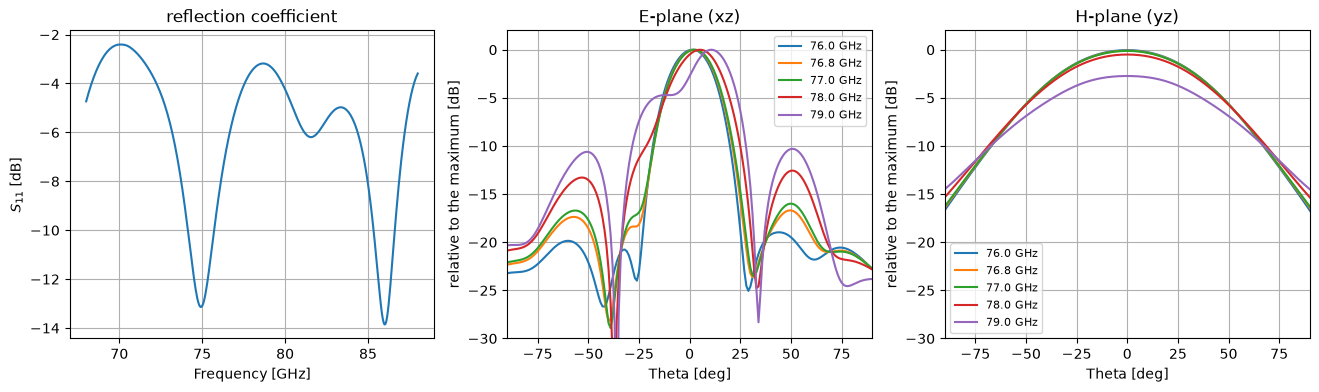

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(a4['f'] / 1e9, to_db(a4['s11']))
ax[0].set_xlabel('Frequency [GHz]'); ax[0].set_ylabel('$S_{11}$ [dB]'); ax[0].set_title('reflection coefficient')
for k, fk in enumerate(fs):
    ax[1].plot(theta, pat[k, :, 0], label='{:.1f} GHz'.format(fk / 1e9))
    ax[2].plot(theta, pat[k, :, 1], label='{:.1f} GHz'.format(fk / 1e9))
ax[1].set_title('E-plane (xz)'); ax[2].set_title('H-plane (yz)')
for a in ax[1:]:
    a.set_xlim(-90, 90); a.set_ylim(-30, 2); a.set_xlabel('Theta [deg]'); a.set_ylabel('relative to the maximum [dB]'); a.legend(fontsize=8)
for a in ax:
    a.grid()

* At 76 GHz the E-plane beam is 22 deg wide, much narrower than that of the single patch, because the four patches are arranged along $x$; the H-plane beam (72 deg) is as wide as that of a single patch. The maximum directivity is 13.4 dBi, about 6 dB more than that of the single patch.
* With increasing frequency the beam moves toward $+x$: 1 deg at 76 GHz, 2 deg at 76.8 and 77 GHz, 5 deg at 78 GHz and 11 deg at 79 GHz.
* At 79 GHz a second lobe appears at $-12$ deg, 4.7 dB below the maximum: the single main lobe starts to break up above this frequency.

### 2.3 Element pattern $\times$ array factor

In [01](./01_beam_pattern.ipynb) the beam pattern of the ULA was derived for isotropic elements.
Here the 4-patch array is modeled in the same way: the pattern is the element pattern (the designed single patch of Section 1) times the array factor of four elements.
The elements are at the centers of the patches.
The excitation phase of each element is given by the electrical length of the transmission line between the patch centers: the half of each patch and the line between them, with the effective permittivity of each microstrip (Hammerstad formula).
The amplitudes are uniform, or proportional to the patch width as a simple model of the taper.

pitch [mm]: [2.31 2.19 2.31]  eps_eff(line) = 2.25


Text(0.5, 1.0, 'E-plane at 77 GHz')

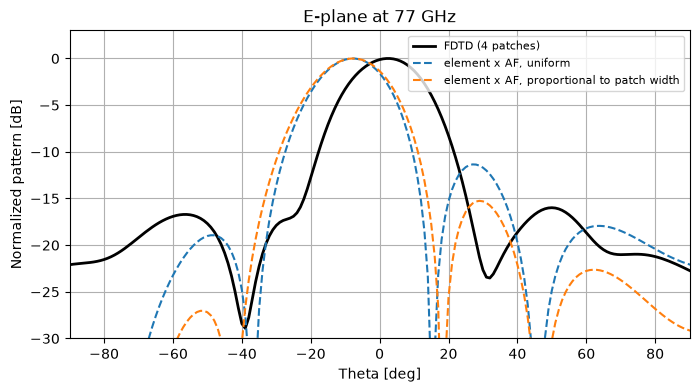

In [11]:
from openEMS.physical_constants import C0
from patch_antenna import MIL, RO3003

epsr, h = RO3003['epsr'], RO3003['h']

def eps_eff(w):
    # Hammerstad formula of microstrip line
    if w / h < 1:
        return (epsr + 1) / 2 + (epsr - 1) / 2 * ((1 + 12 * h / w) ** -0.5 + 0.04 * (1 - w / h) ** 2)
    return (epsr + 1) / 2 + (epsr - 1) / 2 * (1 + 12 * h / w) ** -0.5

# patch lengths (C), widths (E), and the lengths of the lines between them (B), in mm (Table 7)
T7 = TABLE7
C = np.array([T7['C1'], T7['C2'], T7['C2'], T7['C1']]) * MIL
E = np.array([T7['E1'], T7['E2'], T7['E2'], T7['E1']]) * MIL
B = np.array([T7['B2'], T7['B3'], T7['B4']]) * MIL
F3 = T7['F3'] * MIL

n_patch = np.array([eps_eff(w) for w in E])
n_line = eps_eff(F3)
# center positions and electrical lengths (in units of the free-space length) between the centers
x = np.concatenate([[0], np.cumsum(C[:-1] / 2 + B + C[1:] / 2)])
ell = C[:-1] / 2 * np.sqrt(n_patch[:-1]) + B * np.sqrt(n_line) + C[1:] / 2 * np.sqrt(n_patch[1:])
ell = np.concatenate([[0], np.cumsum(ell)])
print('pitch [mm]:', np.round(np.diff(x), 3), ' eps_eff(line) = {:.2f}'.format(n_line))

th = a4['theta']
elem = 10 ** (results['design']['pattern'][:, 0] / 20)   # E-plane pattern of the designed single patch (field)

def model(f, amp):
    k0 = 2 * np.pi * f / C0 * 1e-3          # [rad/mm]
    s = np.sin(np.deg2rad(th))
    af = (amp[None, :] * np.exp(1j * (k0 * x[None, :] * s[:, None] - k0 * ell[None, :]))).sum(axis=1)
    p = 20 * np.log10(np.abs(af) * elem)
    return p - p.max()

amps = {'uniform': np.ones(4), 'proportional to patch width': E / E.mean()}
k77 = list(fs / 1e9).index(77)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(th, pat[k77, :, 0], 'k', lw=2, label='FDTD (4 patches)')
for name, amp in amps.items():
    ax.plot(th, model(fs[k77], amp), '--', label='element x AF, ' + name)
ax.set_xlim(-90, 90); ax.set_ylim(-30, 3); ax.grid(); ax.legend(fontsize=8)
ax.set_xlabel('Theta [deg]'); ax.set_ylabel('Normalized pattern [dB]'); ax.set_title('E-plane at 77 GHz')

The main lobe of the model has a similar width as the simulation at 77 GHz (20 to 22 deg against 22 deg): the narrow E-plane beam comes from the four patches arranged along $x$, as for the arrays of 01.
The direction of the beam (about $-8$ deg against $+2$ deg) is not reproduced by this simple model, which leaves out, for example, the coupling between the patches and the actual amplitude and phase at each patch.

### 2.4 Comparison with the TI document

Fig. 18 of the TI document shows the simulated gain of RX Array A, RX1 at 76 GHz, with the 3 dB beamwidth and the maximum in its legend.
The conditions of the two simulations differ:

| | TI Fig. 18 | this notebook |
| ---- | ---- | ---- |
| model | RX1 on the board: the other elements of the array, the dummy elements, the copper pour, the vias, the whole board | the 4-patch element alone on a ground plane $\pm 3$ mm wide |
| feed | GCPW with its matching | plain microstrip line |
| quantity | gain (with the losses) | directivity (no losses) |

In [12]:
ti = {'E-plane': (22.26, 10.17), 'H-plane': (62.89, 10.87)}  # (3 dB beamwidth [deg], max gain [dB]) read from Fig. 18
D76 = 10 * np.log10(a4['Dmax'][k76])
print('76 GHz      3dB BW [deg] (TI / ours)   max [dB] (TI gain / our directivity)')
for plane, col in (('E-plane', 0), ('H-plane', 1)):
    print('{:8s}    {:6.1f} / {:6.1f}            {:6.2f} / {:6.2f}'.format(plane, ti[plane][0], beamwidth(theta, pat[k76, :, col]), ti[plane][1], D76))

76 GHz      3dB BW [deg] (TI / ours)   max [dB] (TI gain / our directivity)
E-plane       22.3 /   22.0             10.17 /  13.44
H-plane       62.9 /   72.0             10.87 /  13.44


The E-plane beamwidth is 22 deg against 22 deg, the H-plane beamwidth 72 deg against 63 deg; the maximum values are not comparable (gain and directivity).
The E-plane curve of Fig. 18, read from the image of the figure (`openems/data/ti_fig18_curves.csv`), is compared below, relative to the main lobe.

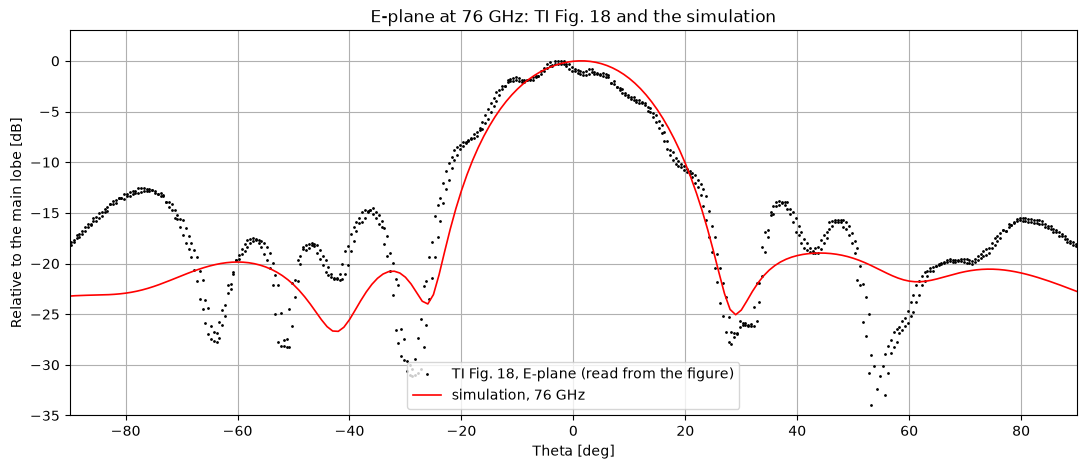

In [13]:
from patch_antenna4 import load_ti_fig18, plot_ti_fig18

fig, ax = plt.subplots(figsize=(13, 5))
plot_ti_fig18(ax, load_ti_fig18(), theta, pat[k76, :, 0], label_sim='simulation, 76 GHz')

* The main lobe agrees: 22 deg against 22 deg.
* The first nulls are at about the same angles ($-26$ and $+29$ deg against $-29$ and $+28$ deg). The first sidelobes are lower in the simulation ($-21$ and $-19$ dB at $-32$ and $+44$ deg against $-15$ and $-14$ dB at $-36$ and $+37$ deg).
* Farther out, the figure of TI has more lobes and is not symmetric; the simulation is smoother. The surroundings of the element on the board, which the simulation does not have, are the likely reason (Section 3).

The patterns of the element in the style of Fig. 18: 0 deg at the top, positive angles to the right.
The radial axis is relative to the maximum of each curve (Fig. 18 plots the gain in dB), and the 3 dB beamwidth is given in the legend.

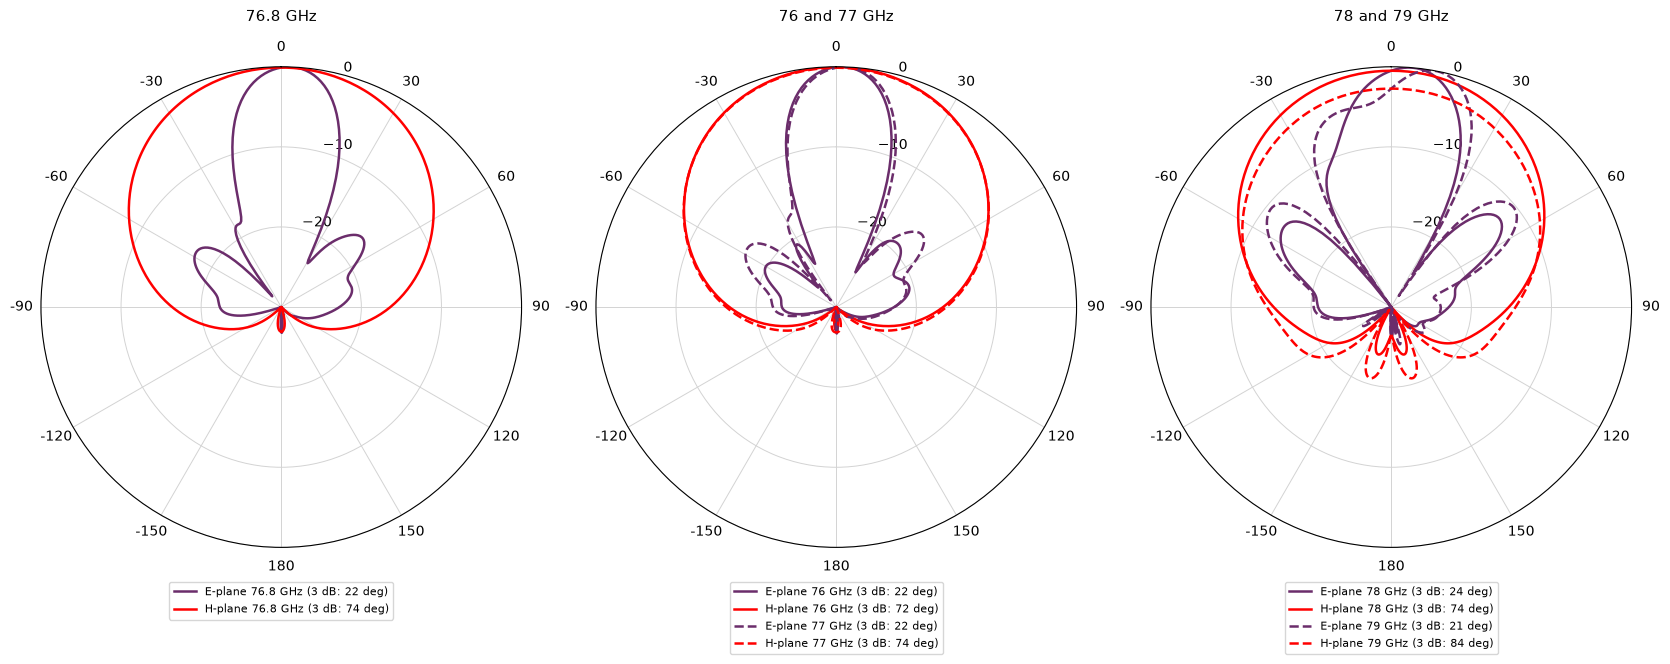

In [14]:
from patch_antenna4 import polar_panels, pattern_curves

curves = lambda f_list: pattern_curves(a4, f_list)     # the E-plane and the H-plane at the frequencies of f_list [GHz]
fig = polar_panels(theta, [('76.8 GHz', curves([76.8])), ('76 and 77 GHz', curves([76, 77])), ('78 and 79 GHz', curves([78, 79]))])

## 3. The element on the board

The simple model of 2.3 leaves out, for example, the coupling between the patches; on the board the element is also coupled to its surroundings.
In this section the element is simulated together with its surroundings, and the change of the response is observed.
As examples, the following parts of the board are taken into account: the neighboring receiving element, the dummy element (a patch that is not connected to a receiver), the copper pour around the elements, and the vias that connect the pour to the ground.
They are also the surroundings of RX1 in Fig. 18 of the TI document, which is a simulation of the element on the board.

The copper of the top layer and the vias are read from the Gerber and drill files of the board (Rev D, Appendix A.5), and three models are computed:

* **isolated element**: the receiving element RX1 and its feed line only;
* **dummy + RX1**: with the dummy element on one side, the copper pour and 16 vias;
* **dummy + RX1 + RX2**: as above, with the next receiving element RX2 on the other side (terminated by a matched load) and 23 vias.

| Item | Setting |
| ---- | ---- |
| copper | the top layer (L1) in a window around RX1 (from $x$ = 134.6 to 138.6 mm of the board, to 140.55 mm with RX2), as zero-thickness PEC; the copper pour with its holes is given as triangles |
| vias | the micro vias between L1 and L2 of the drill file, as PEC cylinders of 0.15 mm diameter |
| substrate and ground | RO3003, 5 mil, over a ground plane 1 mm larger than the window on each side |
| ports | a microstrip port on the feed line of each receiving element, starting in the PML; RX1 is excited, RX2 is a matched load |
| excitation, boundary | as in Section 2 (Gaussian pulse 68 to 88 GHz; PML on all sides, with half a free-space wavelength of air between the substrate and the PML) |
| far field | as in Section 2: from the faces of the near-field to far-field box except the one that the feed lines cross |

In these models the long axis of the element is $y$: the E-plane is the $yz$-plane (Phi = 90) and the H-plane the $xz$-plane (Phi = 0), as in Fig. 18.

<table style="background-color: white"><tr>
<td><img src="../images/05_patch_antenna_board_isolated_model.png" width="380"></td>
<td><img src="../images/05_patch_antenna_board_d_rx1_model.png" width="380"></td>
<td><img src="../images/05_patch_antenna_board_d_rx1_rx2_model.png" width="380"></td>
</tr></table>
<p style="text-align:center"><b>Fig. 5 The models: isolated element, dummy + RX1, dummy + RX1 + RX2 (gold: elements, wheat: copper pour, yellow-green: dummy element, black: vias, red: excited port, blue: matched load; vertical scale x6)</b></p>

In [15]:
from patch_antenna_board import board_window, simulate_board, WINDOW     # with RUN = True it needs the Gerber and drill files of the board (Appendix A.5)

models = {   # name: (arguments of board_window, stored result)
    'isolated element':  (dict(isolate=True), 'patch_antenna_board_isolated.npz'),
    'dummy + RX1':       (dict(), 'patch_antenna_board_d_rx1.npz'),
    'dummy + RX1 + RX2': (dict(window=(WINDOW[0], WINDOW[1], 140.55, WINDOW[3])), 'patch_antenna_board_d_rx1_rx2.npz'),
}
RUN = False    # True: run the simulations (about 20 minutes for the isolated element, 2 to 3 hours for each of the others); False: read the stored results
board = {}
for name, (options, file) in models.items():
    path = os.path.join(data_dir, file)
    if RUN:
        np.savez(path, **simulate_board(board_window(**options), os.path.abspath(os.path.join('../tmp/patch_antenna_board', file[:-4]))))
    board[name] = dict(np.load(path))

In [16]:
from patch_antenna4 import load_ti_fig18
from patch_antenna_board import print_patterns, figure_patterns

ti = load_ti_fig18()      # TI Fig. 18, read from the figure (Phi = 90: E-plane, Phi = 0: H-plane)
print_patterns(board, ti)

76 GHz            | max [dBi] | E: peak, 3 dB width | H: 3 dB width | H: level(+theta) - level(-theta) at 20, 30, 45 deg
TI Fig. 18        |   (10.2)  |   -3 deg,  22.3 deg |   62.9 deg    | +2.3 +3.4 +2.7
isolated element  |   13.20   |    1 deg,  22.0 deg |   75.0 deg    | -0.4 -0.6 -0.4
dummy + RX1       |   13.12   |    4 deg,  16.0 deg |   81.0 deg    | +0.5 +0.4 +0.1
dummy + RX1 + RX2 |   12.91   |    2 deg,  19.0 deg |   93.0 deg    | +1.1 +1.3 +1.0


In [17]:
z = board['dummy + RX1 + RX2']
print('dummy + RX1 + RX2, S parameters [dB] at 76 77 78 79 GHz:')
for key, label in (('S_137_62', 'S11 (RX1)'), ('S_139_58', 'S21 (RX1 -> RX2)')):
    print('  {:18s}'.format(label), ' '.join('{:6.1f}'.format(float(np.interp(g, z['f'] / 1e9, to_db(z[key])))) for g in (76, 77, 78, 79)))

dummy + RX1 + RX2, S parameters [dB] at 76 77 78 79 GHz:
  S11 (RX1)            -8.9   -6.3   -4.9   -4.3
  S21 (RX1 -> RX2)    -16.4  -21.6  -29.1  -21.2


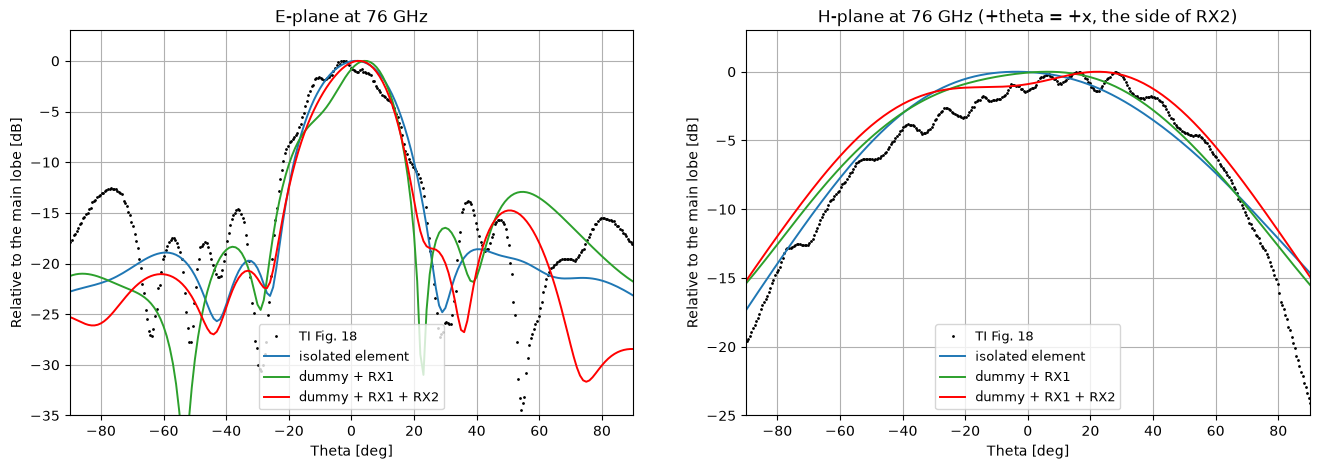

In [18]:
fig = figure_patterns(board, ti)      # the E-plane and the H-plane at 76 GHz, relative to the main lobe

* The E-plane main lobe is 16 to 22 deg wide (22 deg in the TI figure). With the dummy and the neighbor the first sidelobe on the $+\theta$ side rises ($-13$ dB at $+55$ deg and $-15$ dB at $+51$ deg against $-19$ dB at $+41$ deg for the isolated element); on the side of the feed lines ($-\theta$) the sidelobes stay at $-18$ to $-21$ dB. The TI figure has more structure on both sides.
* With RX2 on the $+x$ side and the dummy on the other side, the H-plane becomes asymmetric: the $+\theta$ side is 1.0 to 1.3 dB higher. The TI figure is also higher on this side (2.3 to 3.4 dB).
* The H-plane beam becomes wider (81 and 93 deg) than that of the isolated element (75 deg), while the TI figure gives 63 deg.

## 4. Summary

* A single patch has a broad beam (74 deg $\times$ 80 deg). The patch designed by the textbook formulas resonates 5 % below the design frequency; the length $L$ sets the resonance, the width $W$ the matching, and the size of the ground plane the ripples of the pattern.
* The 4-patch series-fed element has a beam of 22 deg (E-plane) $\times$ 72 deg (H-plane) at 76 GHz, against 22 deg $\times$ 63 deg in the TI document, which is reproduced qualitatively.
* The beam of the element moves toward $+x$ with the frequency (1 deg at 76 GHz, 11 deg at 79 GHz); at 79 GHz the single main lobe starts to break up.
* The element on the board has an asymmetric H-plane pattern, as in the TI figure.
* The element pattern is far from isotropic; the isotropic elements of 02 and 03 are a valid model only near the boresight.

## Appendix A. Setting up openEMS in a conda environment

openEMS is neither on conda-forge nor on PyPI (`conda search openems` finds nothing, `pip index versions openEMS` finds no distribution), so it is built from source **into a conda environment**.
Everything is installed under the prefix of the environment; no root rights are needed, and removing the environment removes openEMS.
The steps are in `tools/setup_openems.sh` and can be repeated: a step that has been done is skipped.

### A.1 Prerequisites

* conda (Miniconda or Anaconda; `mamba` also works) and git, and network access to conda-forge, GitHub and PyPI.
* The compilers, cmake and all the libraries are installed by conda; nothing has to be installed on the system.

### A.2 One command

```bash
tools/setup_openems.sh
# options (environment variables): ENV_NAME (default 4dradar-openems), SRC_DIR (default tmp/openEMS-Project), JOBS (default 8)
```

| Step | What is done |
| ---- | ---- |
| 1/4 | creates the conda environment `4dradar-openems` from `Python/environment_openems.yaml`: Python 3.12, numpy, scipy, h5py, matplotlib, jupyter, the toolchain (`c-compiler`, `cxx-compiler`, `cmake`, `make`, `pkg-config`, `git`), the libraries of openEMS (`libboost-devel`, `hdf5`, `cgal-cpp`, `tinyxml`, `vtk`), `cython`, `setuptools`, `wheel`, and, for the Gerber files of the board, `shapely` and (by pip) `gerbonara` |
| 2/4 | clones `openEMS-Project` from GitHub at the commit `34770fd` (the one checked in this work) with the submodules `fparser`, `CSXCAD`, `openEMS` into `tmp/openEMS-Project` |
| 3/4 | builds and installs the C++ part (fparser, CSXCAD, openEMS) into the environment with cmake: `-DCMAKE_INSTALL_PREFIX=$CONDA_PREFIX -DCMAKE_PREFIX_PATH=$CONDA_PREFIX -DCMAKE_BUILD_TYPE=Release -DBUILD_APPCSXCAD=NO` (the GUI AppCSXCAD is not built) |
| 4/4 | installs the Python bindings `CSXCAD` and `openEMS` (Cython) with `pip install . --no-build-isolation` in `CSXCAD/python` and `openEMS/python`; they need `CSXCAD_INSTALL_PATH` and `OPENEMS_INSTALL_PATH` (the prefix), `CSXCAD_NOSCM=1` and `OPENEMS_NOSCM=1` (no setuptools_scm in the source tree), and `CPATH`, `LIBRARY_PATH` pointing into the prefix |

The environment was created in about one minute; the versions at the time of the check included boost 1.90 and vtk 9.7.0.

If the environment is created by hand instead:

```bash
conda env create -n 4dradar-openems -f Python/environment_openems.yaml     # step 1 only
```

### A.3 Check

```bash
conda activate 4dradar-openems
cd /tmp && python -c "import CSXCAD, openEMS; print('ok')"
# a tutorial of the source tree (a patch antenna, 14 seconds on the PC of this work):
cp tmp/openEMS-Project/openEMS/python/Tutorials/Simple_Patch_Antenna.py /tmp/ && MPLBACKEND=Agg python /tmp/Simple_Patch_Antenna.py
```

The run prints the size of the mesh, the time steps and the energy, ends at the decay of -40 dB and computes the S11 and the far field.

### A.4 Use in this repository

* The simulations of this notebook are in `Python/` (`patch_antenna.py`, `patch_antenna4.py`, `patch_antenna_board.py`); `Python/openems` holds the scripts that check the design data and their figures. This notebook runs in `4dradar-openems`; the notebooks 00 to 03 run in `4dradar-simulation` (`Python/environment_minimum.yaml`).
* The output of a simulation is written under `tmp/` (not in the repository). **Give the simulation directory as an absolute path**; openEMS changes the working directory during a run, and a relative path made the post-processing fail.
* There is no GUI to look at the geometry. Two substitutes are used: the argument `write_xml=True` of the simulation functions (`simulate_patch`, `simulate_element`, `simulate_board`) writes the structure (CSX) of a model, whose mesh lines and primitives can be compared with another model, and the geometry is drawn with OpenSCAD. The `.scad` files (`05_patch_models.scad` for the single patch and the 4-patch element, `05_gerber_models.scad` for the Gerber-based models) and the scripts that render them (`render_05.sh`, `render_05_models.sh`) are in `images/cad`; the figures are written by running the script, e.g. `bash images/cad/render_05.sh` (OpenSCAD and a virtual display `xvfb-run` are needed; the figures of this work were made in a container). The data of the Gerber-based models (`images/cad/data`) are exported from the geometry given to openEMS (`patch_antenna_board.write_scad`; `python patch_antenna_board.py scad`), so that the drawing shows the model that was simulated.

### A.5 Design data of the board (Section 3)

The design files of the MMWCAS-RF-EVM are listed in Section 3.1 of the user's guide (SWRU553A, p. 38):

* MMWCAS-RF-EVM CAD Files Revision C: http://www.ti.com/lit/zip/TIDRZZ6
* MMWCAS-RF-EVM CAD Files Revision D: http://www.ti.com/lit/zip/TIDM464

The models of Section 3 use Revision D (the antennas of Revisions C and D are the same).
The copper of the top layer L1 is read from the Gerber file (`PROC054D.GTL`) and the micro vias between L1 and L2 from the NC drill file (`PROC054D.TX1`, Excellon format), in `gerber_geometry.py`:

* [gerbonara](https://pypi.org/project/gerbonara/) reads the Gerber and the Excellon files; every graphic object (region, line, arc, flash) is converted to a polygon in mm;
* [shapely](https://pypi.org/project/shapely/) unites the polygons of a window of the board (so that the dummy element connected to the copper pour is one polygon with it), clips them, and splits the copper pour with its holes into triangles (constrained Delaunay triangulation), which openEMS accepts as polygons.

Both are installed in `4dradar-openems` (`Python/environment_openems.yaml`).